# 05 · Backtest of the simple rules

Before building any model, I test the simple rules honestly: how much does
"just wait until N days out" actually save, and how do I pick N without
cheating?

**Key takeaways**
1. **For a typical trip, waiting blindly loses money.** From 45, 30, 21 or
   14 days out, every "wait until N days out" rule has a negative average %
   saved. Starting 60 days out is the exception: waiting until about 3–4
   weeks out saves around 8%.
2. **Dollars and percent disagree, and that's informative.** Waiting tends
   to pay on *expensive* tickets and backfire on *cheap* ones. Averaged per
   trip it looks bad, and weighted by fare it looks good. Starting 60 days
   out, waiting until 21 days out saves 6% on tickets under $200 but 20% on
   tickets over $500.
3. **Picking N without peeking gives "buy now" every time.** Learning only
   from trips that had already departed, the walk-forward rule never found
   a reason to wait.
4. So the model's job is **knowing which trips to wait on**. Today's fare
   compared with the route's usual level looks like the key signal.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from flight_pricing.backtest import (START_DAYS, buy_day, decision_date, eligible, fixed_day_rule,
                                     hindsight_best, load_fare_matrix, price_paid, score)
from flight_pricing.data import connect
from flight_pricing.plotting import SERIES, use_style

use_style()
con = connect()
trips, F = load_fare_matrix(con, full_window_only=False)
flight = pd.to_datetime(trips.flightDate)


def fixed_rule_pct(idx, s, n_days):
    """Per-trip % saved by 'wait until n_days out', starting s days out."""
    paid = price_paid(F[idx], buy_day(F[idx], fixed_day_rule(F[idx], n_days), s))
    return (F[idx, s] - paid) / F[idx, s]

## Which trips can be tested

A trip can be tested from a starting point $s$ only if prices were
collected for its whole window, from $s$ days out to departure. Unlike
notebook 04, I now use every trip that qualifies for each starting point,
not just trips with all 60 days. That gives 15k to 36k trips per starting
point.

In [2]:
pd.Series({f"{s} days out": eligible(trips, F, s).sum() for s in START_DAYS},
          name="trips").to_frame().T

,60 days out,45 days out,30 days out,21 days out,14 days out
trips,15333,24565,29505,32989,35549


## What does waiting until N days out save?

For each starting point, I try every possible N and average the % saved
over all trips. **This uses all the data at once, so it's for exploring
only**. Picking N this way would be cheating, and the next section fixes
that.

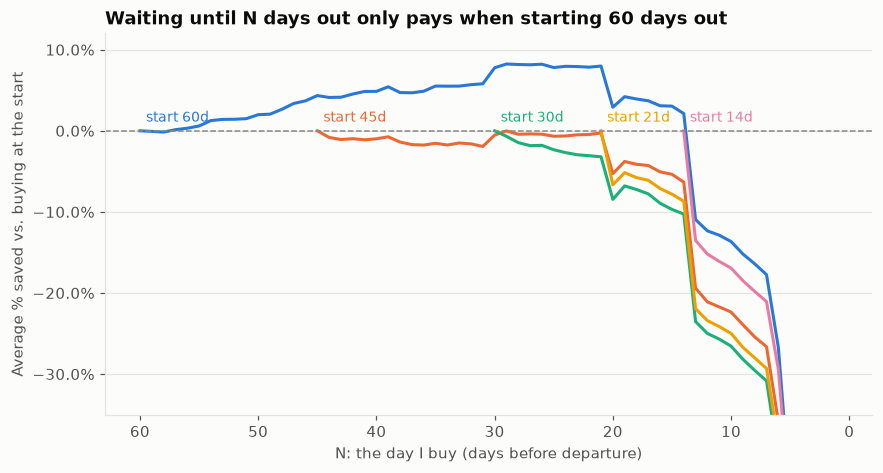

,start 60d,start 45d,start 30d,start 21d,start 14d
buy 45d out,0.043,0.000,NaN,NaN,NaN
buy 30d out,0.078,-0.005,0.000,NaN,NaN
buy 21d out,0.080,-0.003,-0.032,0.000,NaN
buy 14d out,0.021,-0.063,-0.103,-0.087,0.000
buy 7d out,-0.177,-0.266,-0.308,-0.293,-0.211


In [3]:
landscape = {}
for s in START_DAYS:
    idx = np.flatnonzero(eligible(trips, F, s))
    landscape[s] = pd.Series({n: np.nanmean(fixed_rule_pct(idx, s, n)) for n in range(1, s + 1)})

fig, ax = plt.subplots(figsize=(9, 4.5))
for s, color in zip(START_DAYS, SERIES):
    ax.plot(landscape[s].index, landscape[s].values, color=color)
    ax.annotate(f"start {s}d", (s, 0), xytext=(4, 6), textcoords="offset points",
                color=color, fontsize=9)
ax.axhline(0, color="#8a8984", linewidth=1, linestyle="--")
ax.set_title("Waiting until N days out only pays when starting 60 days out")
ax.set_xlabel("N: the day I buy (days before departure)")
ax.set_ylabel("Average % saved vs. buying at the start")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set_ylim(-0.35, 0.12)
ax.invert_xaxis()
plt.show()

pd.DataFrame({f"start {s}d": {f"buy {n}d out": landscape[s].get(n, np.nan) for n in [45, 30, 21, 14, 7]}
              for s in START_DAYS}).round(3)

Each line starts at 0 on its starting day (buying immediately) and shows
what happens if I hold off until N days out.

- **Starting 60 days out**, waiting until about 3–4 weeks out saves about
  8%. Fares 60 days out tend to sit above the trip's usual level (notebook
  02), so there's room to come down.
- **From every other starting point, the line only goes down.** By 45 days
  out, fares are already at their usual level, and waiting just walks me
  into the late price climb. Waiting until 7 days out costs 18–31%.

- **Every line falls off a cliff right after 21, 14 and 7 days.** Starting
  60 days out, savings hold at about 8% from 29 to 21 days out, then drop to
  3% the very next day. This is the strongest evidence so far for the
  advance-purchase deadlines I guessed at in notebook 02. If I'm going to
  wait, I should buy **before** a deadline, not after it. (Lines below −35%
  run off the chart. Waiting until the last few days is very expensive.)

So "book about 3 weeks out" is only good advice if I'm looking early, and
only if I buy before the 21-day mark. If I'm already within ~6 weeks, the
simple answer is to buy.

## Picking N honestly: walk-forward

**Lookahead bias** is using information I wouldn't have had at decision
time. Picking the best N from the chart above is lookahead: it uses trips
from the same months I'm testing on.

The honest version is **walk-forward**:

1. Group trips by the **month I make the decision** (the search date $s$
   days before the flight).
2. For each test month, learn N only from trips that **had already
   departed** before that month began. A trip's outcome isn't known until
   its flight leaves, so a trip still in progress can't be used.
3. Apply that N to the test month, then move forward a month and repeat.

Point 2 is the subtle one. Training only on trips *searched* before the
test month would still leak, because some of those trips depart after the
test month starts.

In [4]:
folds = []
for s in START_DAYS:
    ok = eligible(trips, F, s)
    month = decision_date(trips, s).dt.to_period("M")
    for m in sorted(month[ok].unique()):
        test = ok & (month == m).to_numpy()
        train = ok & (flight < m.start_time).to_numpy()
        if train.sum() < 500:
            continue  # not enough departed trips to learn from yet
        train_idx = np.flatnonzero(train)
        n_star = max(range(1, s + 1), key=lambda n: np.nanmean(fixed_rule_pct(train_idx, s, n)))
        test_idx = np.flatnonzero(test)
        folds.append({"start": s, "test_month": str(m), "train_trips": train.sum(),
                      "test_trips": test.sum(), "chosen_N": n_star,
                      "test_pct_saved": np.nanmean(fixed_rule_pct(test_idx, s, n_star))})
folds = pd.DataFrame(folds)
folds.round(3)

,start,test_month,train_trips,test_trips,chosen_N,test_pct_saved
0,60,2022-07,1628,6149,60,0.0
1,45,2022-07,5148,7252,45,0.0
2,45,2022-08,9827,4445,45,0.0
3,30,2022-06,3276,5875,30,0.0
4,30,2022-07,8190,7252,30,0.0
5,30,2022-08,14299,6785,30,0.0
6,30,2022-09,21550,1403,30,0.0
7,21,2022-06,5349,6782,21,0.0
8,21,2022-07,10302,7253,21,0.0
9,21,2022-08,17552,7014,21,0.0


I pick N by **average % saved**, so every trip counts equally. Learning
only from departed trips, the walk-forward rule picks **"buy now" in every
fold**, including for the 60-day start. For that start,
the only fold with enough history is July, and it learned from trips that
departed in late June. That's too little data, from a different part of the
season, so it misses the 8% that the full-data chart shows.

That gap between "looks best on all the data" and "what I could have known
at the time" is exactly what lookahead bias hides.

## Scoreboard: the simple rules on the test months

Every rule is scored on the **same test trips** (the walk-forward test
months), so the comparison is fair. "Best N with hindsight" is included
only to show what lookahead would claim. It's not a real strategy.

In [5]:
rows = []
for s in START_DAYS:
    test_months = set(folds.loc[folds.start == s, "test_month"])
    if not test_months:
        continue
    month = decision_date(trips, s).dt.to_period("M").astype(str)
    test = eligible(trips, F, s) & month.isin(test_months).to_numpy()
    idx = np.flatnonzero(test)
    start_fare = F[idx, s]

    def rule(n):
        return price_paid(F[idx], buy_day(F[idx], fixed_day_rule(F[idx], n), s))

    chosen = folds[folds.start == s].set_index("test_month").chosen_N
    wf_paid = np.full(len(idx), np.nan)
    for m, n in chosen.items():
        in_m = (month.to_numpy()[idx] == m)
        wf_paid[in_m] = rule(n)[in_m]

    candidates = {"Buy now": rule(s),
                  "Walk-forward N": wf_paid,
                  **{f"Buy {n}d out": rule(n) for n in [21, 14] if n < s},
                  f"Best N with hindsight ({landscape[s].idxmax()}d)": rule(landscape[s].idxmax()),
                  "Hindsight best day (ceiling)": hindsight_best(F[idx], s)}
    for name, paid in candidates.items():
        rows.append(score(start_fare, paid).rename((f"start {s}d", name)))

scoreboard = pd.DataFrame(rows)
scoreboard.index = pd.MultiIndex.from_tuples(scoreboard.index, names=["start", "rule"])
scoreboard[["trips", "avg_saved_usd", "avg_saved_pct", "total_saved_pct", "share_lost_money"]].round(3)

trips  avg_saved_usd  avg_saved_pct  \
start     rule                                                                  
start 60d Buy now                        6149.0          0.000          0.000   
          Walk-forward N                 6149.0          0.000          0.000   
          Buy 21d out                    6149.0         12.818          0.056   
          Buy 14d out                    6149.0          1.640         -0.049   
          Best N with hindsight (29d)    6149.0         16.768          0.104   
          Hindsight best day (ceiling)   6149.0         37.801          0.284   
start 45d Buy now                       11697.0          0.000          0.000   
          Walk-forward N                11697.0          0.000          0.000   
          Buy 21d out                   11697.0          5.496         -0.005   
          Buy 14d out                   11697.0         -6.584         -0.129   
          Best N with hindsight (45d)   11697.0          0.000          0.000   
          Hindsight best day (ceiling)  11697.0         27.939          0.208   
start 30d Buy now                       21315.0          0.000          0.000   
          Walk-forward N                21315.0          0.000          0.000   
          Buy 21d out                   21315.0          4.288         -0.009   
          Buy 14d out                   21315.0         -1.371         -0.089   
          Best N with hindsight (30d)   21315.0          0.000          0.000   
          Hindsight best day (ceiling)  21315.0         31.197          0.180   
start 21d Buy now                       24558.0          0.000          0.000   
          Walk-forward N                24558.0          0.000          0.000   
          Buy 14d out                   24558.0         -4.272         -0.087   
          Best N with hindsight (21d)   24558.0          0.000          0.000   
          Hindsight best day (ceiling)  24558.0         24.699          0.136   
start 14d Buy now                       26044.0          0.000          0.000   
          Walk-forward N                26044.0          0.000          0.000   
          Best N with hindsight (14d)   26044.0          0.000          0.000   
          Hindsight best day (ceiling)  26044.0         15.689          0.083   

                                        total_saved_pct  share_lost_money  
start     rule                                                             
start 60d Buy now                                 0.000             0.000  
          Walk-forward N                          0.000             0.000  
          Buy 21d out                             0.105             0.278  
          Buy 14d out                             0.013             0.451  
          Best N with hindsight (29d)             0.137             0.217  
          Hindsight best day (ceiling)            0.310             0.000  
start 45d Buy now                                 0.000             0.000  
          Walk-forward N                          0.000             0.000  
          Buy 21d out                             0.047             0.327  
          Buy 14d out                            -0.056             0.552  
          Best N with hindsight (45d)             0.000             0.000  
          Hindsight best day (ceiling)            0.238             0.000  
start 30d Buy now                                 0.000             0.000  
          Walk-forward N                          0.000             0.000  
          Buy 21d out                             0.031             0.306  
          Buy 14d out                            -0.010             0.518  
          Best N with hindsight (30d)             0.000             0.000  
          Hindsight best day (ceiling)            0.223             0.000  
start 21d Buy now                                 0.000             0.000  
          Walk-forward N                          0.000             0.000  
          Buy 14d ou

How to read it:

- **Buy now** saves $0 by definition. It's the baseline.
- **Walk-forward N** is the honest simple rule. It lands on "buy now"
  everywhere, so it also saves $0.
- **Buy 21d out** shows the $-vs-% split. Starting 45 days out it saves
  **+$5.50 per trip** and **4.7% of total spend**, yet the **average trip
  loses 0.5%**, and **a third of trips lose money**. A few expensive trips
  that drop a lot outweigh many cheap trips that rise a little.
- **Buy 14d out** loses on more than half of trips from most starting
  points.
- **Hindsight best day** is the ceiling: 10–28% depending on the start.
  There's real money between $0 and that ceiling, but no blanket rule
  captures it.

## Does it depend on how expensive the ticket is?

Starting 60 days out and waiting until 21 days out, split by the starting
fare:

In [6]:
s = 60
idx = np.flatnonzero(eligible(trips, F, s))
pct = fixed_rule_pct(idx, s, 21)
usd = pct * F[idx, s]
band = pd.cut(F[idx, s], [0, 200, 500, np.inf], labels=["under $200", "$200–500", "over $500"])
pd.DataFrame({"band": band, "pct": pct, "usd": usd}).groupby("band", observed=True).agg(
    trips=("pct", "size"), avg_saved_pct=("pct", "mean"), avg_saved_usd=("usd", "mean"),
    share_lost_money=("pct", lambda x: (x < 0).mean())).round(3)

,trips,avg_saved_pct,avg_saved_usd,share_lost_money
band,,,,
under $200,11718,0.059,9.777,0.290
$200–500,3493,0.147,41.648,0.221
over $500,122,0.201,113.795,0.131


Waiting helps a lot more on expensive tickets, even in percent: 6% under
$200, 15% for $200–500 and 20% over $500. It also backfires less often (29%
of cheap trips lose money vs. 13% of expensive ones). *My guess:* a high
starting fare is often temporarily high and tends to come back down, while
a low fare has little room to fall.

That's the signal a model can use. **How today's fare compares with the
route's usual level** should tell me which trips are worth waiting on.

## Next: notebook 06

Build a model that decides **trip by trip** whether to wait, using only
what's known that day (days to departure, today's fare vs. the route's
usual level, recent moves, deadline proximity), and score it on exactly
these walk-forward test months.